# Relatório — reprodução do detector do Kim (baseline binário)

O baseline (Kim *et al.*) é um IDS **binário** (normal × ataque) para SOME/IP, com XGBoost
sobre **12 features** comportamentais (sem cabeçalho). O Kim publicou apenas o **dataset**;
reimplementamos o detector a partir do artigo. Este relatório:

1. **Reproduz a detecção** do Kim — features dele, split 50/50, hiperparâmetros da Tabela 2,
   limiar de máximo F1 — e confere o número publicado (**F1 ≈ 0,97**).
2. **Mede a latência** do pipeline no **mesmo setup** da nossa C1 (extração das 12 features
   pela mesma engine, a partir do PCAP, + mesmo harness), para a comparação de eficiência.

O Kim reporta **0,556 ms/pacote** (Threadripper 7970X, 1 núcleo); medimos aqui no EPYC/CPU.


## 0. Ambiente


In [1]:
import os, sys
REPO = "someip-xgboost-reproduction"
def in_repo(): return os.path.isdir("src") and os.path.isdir("data")
if not in_repo() and os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
if not in_repo() and os.path.isdir(REPO): os.chdir(REPO)
if not in_repo():
    os.system("git lfs install; git clone https://github.com/GuilhermeFrick/%s.git" % REPO); os.chdir(REPO)
os.system("%s -m pip install -q numpy scapy 'xgboost==3.3.0' scikit-learn matplotlib pandas" % sys.executable)
import platform, numpy as np
print("Plataforma :", platform.platform()); print("Processador:", platform.processor() or platform.machine())
print("CPUs       :", os.cpu_count())
import shutil; DEVICE = "cuda" if shutil.which("nvidia-smi") else "cpu"
print("device     :", DEVICE)
MAX_PACKETS = None   # p/ a parte de latência (extração do PCAP); None = completo


Plataforma : Linux-6.17.0-1017-aws-x86_64-with-glibc2.39
Processador: x86_64
CPUs       : 8
device     : cpu


## 1. Dados — features do Kim (12 features, binário)
O dataset traz os vetores de **12 features** já extraídos e o **split 50/50** do Kim
(`X_train`/`X_test`, rótulo 0=normal, 1=ataque), versionados via Git LFS.


In [2]:
import numpy as np
def _load(name):
    npz = os.path.join("data", name + ".npz")
    return np.load(npz)["a"] if os.path.exists(npz) else np.load(os.path.join("data", name + ".npy"))
Xtr, Xte = np.asarray(_load("X_train")), np.asarray(_load("X_test"))
ytr, yte = _load("y_train"), _load("y_test")
print("treino:", Xtr.shape, "| teste:", Xte.shape)
for nm, y in [("treino", ytr), ("teste", yte)]:
    u, c = np.unique(y, return_counts=True); d = {int(k): int(v) for k, v in zip(u, c)}
    print(f"  {nm}: {d}  (ataque% = {100*d.get(1,0)/len(y):.2f})")


treino: (7116674, 12) | teste: (7116673, 12)
  treino: {0: 6285515, 1: 831159}  (ataque% = 11.68)
  teste: {0: 6285514, 1: 831159}  (ataque% = 11.68)


## 2. Reprodução do detector do Kim
XGBoost **binário** com os hiperparâmetros da Tabela 2 do artigo (1000 árvores, `max_depth`
6, `lr` 0,05, `subsample`/`colsample` 0,8, `λ`=1). Para o desbalanceamento usamos
`scale_pos_weight` (alternativa ao CTGAN; o Kim usa CTGAN). O limiar de decisão é ajustado
para **maximizar o F1** da classe ataque (o Kim ajusta para ~0,36).


In [3]:
from xgboost import XGBClassifier
PARAMS = dict(objective="binary:logistic", n_estimators=1000, max_depth=6, learning_rate=0.05,
              subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, gamma=0.0, min_child_weight=1,
              tree_method="hist", device=DEVICE, n_jobs=-1, eval_metric=["auc", "aucpr"])
spw = float((ytr == 0).sum() / max((ytr == 1).sum(), 1))      # scale_pos_weight
print("scale_pos_weight =", round(spw, 2))
clf_kim = XGBClassifier(**PARAMS, scale_pos_weight=spw)
clf_kim.fit(Xtr, ytr, eval_set=[(Xte, yte)], verbose=False)
scores = clf_kim.predict_proba(Xte)[:, 1]


scale_pos_weight = 7.56


In [4]:
# Limiar de máximo F1 (classe ataque) a partir da curva Precision-Recall
from sklearn.metrics import (precision_recall_curve, roc_auc_score, average_precision_score,
                             f1_score, precision_score, recall_score, accuracy_score, confusion_matrix)
prec, rec, thr = precision_recall_curve(yte, scores)
f1c = 2*prec*rec/(prec+rec+1e-12); i = int(np.nanargmax(f1c[:-1]))
THRESHOLD = float(thr[i]); ypred = (scores >= THRESHOLD).astype(int)
ROC = roc_auc_score(yte, scores); PR = average_precision_score(yte, scores)
F1a = f1_score(yte, ypred); F1w = f1_score(yte, ypred, average="weighted"); F1m = f1_score(yte, ypred, average="macro")
import pandas as pd
print("ROC-AUC = %.4f | PR-AUC = %.4f | limiar = %.4f" % (ROC, PR, THRESHOLD))
pd.DataFrame([{"F1 (ataque)": F1a, "F1 ponderado": F1w, "F1 macro": F1m,
               "precision": precision_score(yte, ypred), "recall": recall_score(yte, ypred),
               "accuracy": accuracy_score(yte, ypred)}]).round(4)


ROC-AUC = 0.9874 | PR-AUC = 0.9313 | limiar = 0.8081


,F1 (ataque),F1 ponderado,F1 macro,precision,recall,accuracy
0,0.8441,0.9661,0.9132,0.9838,0.7391,0.9681


### 2.1 Matriz de confusão e curvas


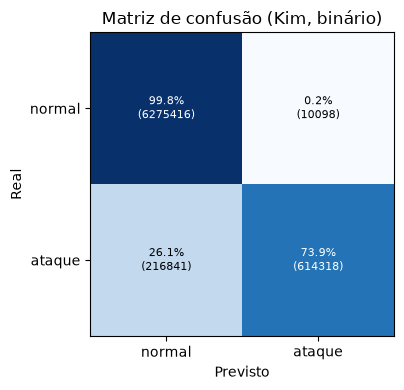

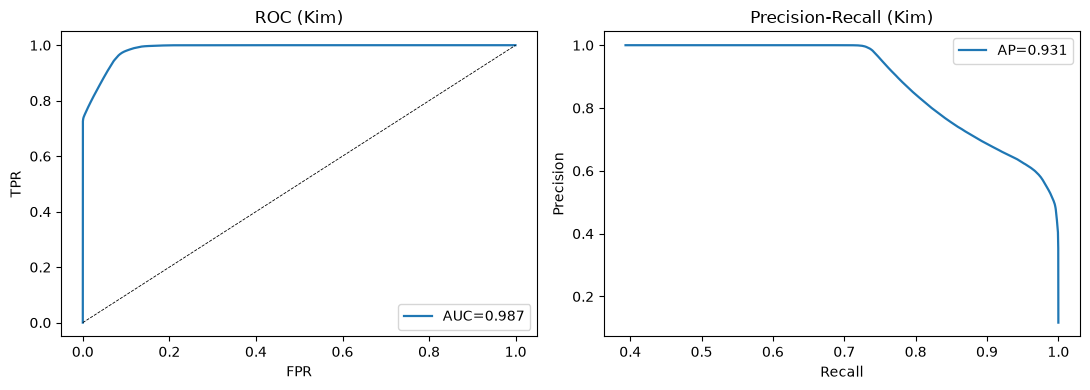

In [5]:
import matplotlib.pyplot as plt
cm = confusion_matrix(yte, ypred); cmn = cm/cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(4.5, 4)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["normal", "ataque"]); ax.set_yticklabels(["normal", "ataque"])
ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusão (Kim, binário)")
for a in range(2):
    for b in range(2): ax.text(b, a, "%.1f%%\n(%d)" % (cmn[a, b]*100, cm[a, b]), ha="center", va="center", fontsize=8, color="white" if cmn[a, b] > 0.5 else "black")
plt.tight_layout(); plt.show()
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(yte, scores); s = max(len(fpr)//2000, 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(fpr[::s], tpr[::s], lw=1.6, label="AUC=%.3f" % ROC); a1.plot([0, 1], [0, 1], "k--", lw=.6)
a1.set_xlabel("FPR"); a1.set_ylabel("TPR"); a1.set_title("ROC (Kim)"); a1.legend()
s2 = max(len(rec)//2000, 1); a2.plot(rec[::s2], prec[::s2], lw=1.6, label="AP=%.3f" % PR)
a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title("Precision-Recall (Kim)"); a2.legend()
plt.tight_layout(); plt.show()


## 3. Latência — mesmo setup da C1
Para comparar a eficiência de igual para igual, extraímos as **12 features do Kim** com a
**mesma engine da C1** (parser + byte-model), a partir do PCAP, e medimos a latência com o
**mesmo harness** por estágio. A seguir, todo o motor (byte-model, parser e extrator das 12
features) e a medição.


### 3.1 Motor: byte-model, parser e extrator das 12 features


In [6]:
import time, socket
from collections import defaultdict, deque
from dataclasses import dataclass, field
from scapy.utils import RawPcapReader

class ByteModel:
    def __init__(self, L, alpha=1.0):
        self.L = int(L); self.alpha = float(alpha)
        self._counts = np.zeros((self.L, 256), dtype=np.float64); self.logP = None
    def update(self, payload):
        k = min(len(payload), self.L)
        if k: self._counts[np.arange(k), np.frombuffer(payload[:k], np.uint8)] += 1.0
    def finalize(self):
        P = (self._counts + self.alpha)/(self._counts.sum(1, keepdims=True) + self.alpha*256.0)
        self.logP = np.log(P); return self
    def loglik(self, payload):
        k = min(len(payload), self.L)
        return float(self.logP[np.arange(k), np.frombuffer(payload[:k], np.uint8)].sum()) if k else 0.0
    def cross_entropy(self, payload):
        k = min(len(payload), self.L)
        return float(-self.logP[np.arange(k), np.frombuffer(payload[:k], np.uint8)].sum()/k) if k else 0.0

def hamming(a, b):
    if not a and not b: return 0
    n = min(len(a), len(b))
    if n == 0: return max(len(a), len(b))
    return int(np.count_nonzero(np.frombuffer(a[:n], np.uint8) != np.frombuffer(b[:n], np.uint8)) + abs(len(a)-len(b)))

SD_PORT = 30490; ETH_IPV4 = b"\x08\x00"
def _ip(b): return socket.inet_ntoa(b)
@dataclass(slots=True)
class Pkt:
    ts: float = 0.0; src: str = ""; dst: str = ""; proto: int = 0; sport: int = 0; dport: int = 0
    ip_len: int = 0; is_someip: bool = False; is_sd: bool = False
    service_id: int = -1; method_id: int = -1; msg_type: int = -1; client_id: int = -1
    pl_l4: bytes = b""; pl_someip: bytes = b""; pl_sd: bytes = b""
def parse(raw, ts=0.0):
    if raw[12:14] != ETH_IPV4: return None
    ihl = (raw[14] & 0x0F)*4; proto = raw[23]; ip_len = int.from_bytes(raw[16:18], "big"); l4 = 14+ihl
    p = Pkt(ts=ts, src=_ip(raw[26:30]), dst=_ip(raw[30:34]), proto=proto, ip_len=ip_len)
    if proto == 17: p.sport = int.from_bytes(raw[l4:l4+2], "big"); p.dport = int.from_bytes(raw[l4+2:l4+4], "big"); off = l4+8
    elif proto == 6: p.sport = int.from_bytes(raw[l4:l4+2], "big"); p.dport = int.from_bytes(raw[l4+2:l4+4], "big"); off = l4+(raw[l4+12] >> 4)*4
    else: return None
    p.pl_l4 = raw[off:]
    if len(p.pl_l4) < 16: return p
    p.service_id = int.from_bytes(p.pl_l4[0:2], "big"); p.method_id = int.from_bytes(p.pl_l4[2:4], "big")
    p.client_id = int.from_bytes(p.pl_l4[8:10], "big"); p.msg_type = p.pl_l4[14]; p.is_someip = True; body = p.pl_l4[16:]
    if p.dport == SD_PORT or p.sport == SD_PORT or p.service_id == 0xFFFF: p.is_sd = True; p.pl_sd = body
    else: p.pl_someip = body
    return p
def flow_key(p): return (p.src, p.dst, p.sport, p.dport, p.proto)

L = {"someip": 64, "sd": 80, "l4": 64}; BENIGN_FILE = "benign_traffic.pcap"
ATTACK_FILES = {"dos_noti_flood.pcap": 1, "fuzzy_sd_offer_rand_noti(1).pcap": 1,
                "fuzzy_sd_offer_rand_noti(2).pcap": 1, "fuzzy_sd_offer_rand_noti(3).pcap": 1,
                "mitm_multi_attacker.pcap": 1, "mitm_single_attacker.pcap": 1}   # binário: 1 = ataque
def _ts(meta):
    try: return meta.sec + meta.usec*1e-6
    except Exception: return 0.0
def fit_bytemodels(pcap_dir, max_packets=None):
    models = {k: ByteModel(L[k]) for k in L}; benign_ips = set(); n = 0
    for raw, meta in RawPcapReader(os.path.join(pcap_dir, BENIGN_FILE)):
        n += 1
        if max_packets and n > max_packets: break
        p = parse(raw)
        if p is None: continue
        benign_ips.add(p.src)
        if p.pl_l4: models["l4"].update(p.pl_l4)
        if p.is_sd and p.pl_sd: models["sd"].update(p.pl_sd)
        elif p.pl_someip: models["someip"].update(p.pl_someip)
    for m in models.values(): m.finalize()
    return models, benign_ips

# Extrator das 12 FEATURES DO KIM (idênticas às 12 do baseline da C1):
FEATURE_NAMES_12 = ["ip_time_interval", "someip_loglik", "sd_loglik", "l4_loglik",
                    "someip_entropy", "sd_entropy", "l4_entropy",
                    "someip_change", "sd_change", "l4_change", "ip_len_change", "l4_len_change"]
class FeatureStreamer12:
    def __init__(self): self.last = {}
    def step(self, p, models):
        fk = flow_key(p); st = self.last.get(fk)
        if st is None:
            iat = 0.0; ip_len_chg = 0; l4_len_chg = 0; someip_chg = sd_chg = l4_chg = 0
        else:
            iat = p.ts-st["ts"]; ip_len_chg = p.ip_len-st["ip_len"]; l4_len_chg = len(p.pl_l4)-len(st["l4"])
            l4_chg = hamming(p.pl_l4, st["l4"])
            someip_chg = hamming(p.pl_someip, st["someip"]) if (p.pl_someip or st["someip"]) else 0
            sd_chg = hamming(p.pl_sd, st["sd"]) if (p.pl_sd or st["sd"]) else 0
        someip_ll = models["someip"].loglik(p.pl_someip) if p.pl_someip else 0.0
        sd_ll = models["sd"].loglik(p.pl_sd) if p.pl_sd else 0.0
        l4_ll = models["l4"].loglik(p.pl_l4) if p.pl_l4 else 0.0
        someip_h = models["someip"].cross_entropy(p.pl_someip) if p.pl_someip else 0.0
        sd_h = models["sd"].cross_entropy(p.pl_sd) if p.pl_sd else 0.0
        l4_h = models["l4"].cross_entropy(p.pl_l4) if p.pl_l4 else 0.0
        self.last[fk] = {"ts": p.ts, "ip_len": p.ip_len, "l4": p.pl_l4, "someip": p.pl_someip, "sd": p.pl_sd}
        return (iat, someip_ll, sd_ll, l4_ll, someip_h, sd_h, l4_h, someip_chg, sd_chg, l4_chg, ip_len_chg, l4_len_chg)
print("motor definido (byte-model, parser, extrator de 12 features)")


motor definido (byte-model, parser, extrator de 12 features)


### 3.2 Extração das 12 features do PCAP + modelo binário (p/ a medição)
Baixa o PCAP, extrai as 12 features (mesma engine da C1), e treina um XGBoost binário
(config do Kim) sobre elas — o modelo usado na medição de latência.


In [7]:
if not os.path.exists("data/pcap/benign_traffic.pcap"):
    if not os.path.exists("scripts/download_pcaps.py"):
        os.makedirs("scripts", exist_ok=True)
        os.system("curl -sL https://raw.githubusercontent.com/GuilhermeFrick/someip-ids-multiclass-contentext/main/scripts/download_pcaps.py -o scripts/download_pcaps.py")
    print("baixando PCAPs (~1.9 GB)..."); os.system("%s scripts/download_pcaps.py" % sys.executable)
models_pcap, benign_ips = fit_bytemodels("data/pcap", MAX_PACKETS)
files = [(BENIGN_FILE, 0)] + list(ATTACK_FILES.items())
Xp, yp, counts = [], [], []
for fname, atk in files:
    streamer = FeatureStreamer12(); X, y = [], []; n = 0
    for raw, meta in RawPcapReader("data/pcap/"+fname):
        n += 1
        if MAX_PACKETS and n > MAX_PACKETS: break
        p = parse(raw, _ts(meta))
        if p is None: continue
        X.append(streamer.step(p, models_pcap)); y.append(atk if (atk and p.src not in benign_ips) else 0)
    Xp.append(np.asarray(X, np.float64)); yp.append(np.asarray(y, np.int64)); counts.append(len(y))
Xpcap = np.concatenate(Xp); ypcap = np.concatenate(yp); del Xp, yp
xmin = Xpcap.min(0); xmax = Xpcap.max(0); rng = np.where(xmax > xmin, xmax-xmin, 1.0)
Xpn = ((Xpcap-xmin)/rng).astype(np.float32); del Xpcap
# split temporal 70/30 só para TER um modelo treinado nas features do PCAP (p/ medir latência)
def tsplit(counts, frac=0.70):
    tr, te, s = [], [], 0
    for c in counts: cut = s+int(c*frac); tr.append(np.arange(s, cut)); te.append(np.arange(cut, s+c)); s += c
    return np.concatenate(tr), np.concatenate(te)
itr, ite = tsplit(counts)
clf_lat = XGBClassifier(**PARAMS, scale_pos_weight=float((ypcap[itr] == 0).sum()/max((ypcap[itr] == 1).sum(), 1)))
clf_lat.fit(Xpn[itr], ypcap[itr])
print("modelo binário (12 feat do PCAP) treinado para a medição de latência:", Xpn.shape)


modelo binário (12 feat do PCAP) treinado para a medição de latência: (14233354, 12)


### 3.3 Medição da latência por estágio (1 núcleo, por pacote)


In [8]:
def measure_latency(clf, models, pcap="data/pcap/benign_traffic.pcap", n=1000, warmup=2000):
    streamer = FeatureStreamer12(); t_lay, t_fea, feats = [], [], []; k = 0
    for raw, meta in RawPcapReader(pcap):
        a = time.perf_counter(); p = parse(raw, _ts(meta)); b = time.perf_counter()
        if p is None: continue
        x = streamer.step(p, models); c = time.perf_counter(); k += 1
        if k > warmup: t_lay.append(b-a); t_fea.append(c-b); feats.append(x)
        if len(feats) >= n: break
    Xs = ((np.asarray(feats, np.float64)-xmin)/rng).astype(np.float32)
    booster = clf.get_booster(); _ = booster.inplace_predict(Xs[:256])
    t_clf, t_dec = [], []
    for row in Xs:
        r = row.reshape(1, -1)
        a = time.perf_counter(); pr = booster.inplace_predict(r); b = time.perf_counter()
        _ = (np.asarray(pr) >= THRESHOLD); c = time.perf_counter(); t_clf.append(b-a); t_dec.append(c-b)
    us = lambda v: float(np.mean(v)*1e6)
    ext = us(t_lay)+us(t_fea); inf = us(t_clf)+us(t_dec)
    return {"layer": us(t_lay), "feature": us(t_fea), "classification": us(t_clf),
            "decision": us(t_dec), "extracao": ext, "inferencia": inf, "e2e": ext+inf, "pps": 1e6/(ext+inf)}
LAT = measure_latency(clf_lat, models_pcap)
import pandas as pd
display(pd.DataFrame([{"estágio": s, "us/pkt": LAT[k]} for s, k in
        [("layer (parse)", "layer"), ("feature (12)", "feature"), ("classification", "classification"),
         ("decision (limiar)", "decision"), ("EXTRAÇÃO", "extracao"), ("INFERÊNCIA", "inferencia"),
         ("END-TO-END", "e2e")]]).round(2))
print("end-to-end: %.1f us/pkt (%.0f pps)" % (LAT["e2e"], LAT["pps"]))


,estágio,us/pkt
0,layer (parse),2.54
1,feature (12),9.45
2,classification,225.25
3,decision (limiar),2.75
4,EXTRAÇÃO,11.99
5,INFERÊNCIA,228.01
6,END-TO-END,240.00


end-to-end: 240.0 us/pkt (4167 pps)


## 4. Resumo
Reprodução do detector do Kim (binário) e seu custo no mesmo setup da C1.


In [9]:
print("=== DETECÇÃO (reprodução do Kim, split 50/50) ===")
print("  F1 (ataque)   : %.4f" % F1a)
print("  F1 ponderado  : %.4f  (artigo: ~0.97)" % F1w)
print("  ROC-AUC       : %.4f | PR-AUC: %.4f" % (ROC, PR))
print("=== LATÊNCIA (1 núcleo, por pacote, EPYC) ===")
print("  extração      : %.1f us/pkt" % LAT["extracao"])
print("  inferência    : %.1f us/pkt" % LAT["inferencia"])
print("  end-to-end    : %.1f us/pkt (%.0f pps)" % (LAT["e2e"], LAT["pps"]))
print("  (Kim publicou 0.556 ms/pkt = 556 us em Threadripper 7970X, 1 nucleo)")


=== DETECÇÃO (reprodução do Kim, split 50/50) ===
  F1 (ataque)   : 0.8441
  F1 ponderado  : 0.9661  (artigo: ~0.97)
  ROC-AUC       : 0.9874 | PR-AUC: 0.9313
=== LATÊNCIA (1 núcleo, por pacote, EPYC) ===
  extração      : 12.0 us/pkt
  inferência    : 228.0 us/pkt
  end-to-end    : 240.0 us/pkt (4167 pps)
  (Kim publicou 0.556 ms/pkt = 556 us em Threadripper 7970X, 1 nucleo)
